# Surface Code Decoding under Circuit-Level Noise: MWPM vs. a Neural-Network Decoder
### Numerical simulation with Stim, Minimum-Weight Perfect Matching (PyMatching) and a PyTorch neural decoder

**Goal.** Simulate the rotated surface code in a *memory experiment*: encode a logical qubit, run $d$ rounds of stabilizer measurement under noise, decode the syndrome history, and check whether the logical qubit survived. Then ask whether a **neural network trained only on simulated syndromes** can decode better than the standard matching decoder, and at what cost in latency.

**Pipeline**
1. Generate the noisy syndrome-extraction circuit (Stim).
2. Convert it into a *detector error model* (DEM): which physical faults flip which detectors / the logical observable.
3. Build a matching graph from the DEM and decode sampled syndromes with MWPM (PyMatching).
4. Sweep code distance $d$ and physical error rate $p$, and locate the threshold $p_{th}$ where the curves cross.
5. Below threshold, measure the error-suppression factor $\Lambda = \varepsilon_d / \varepsilon_{d+2}$.
6. Train a neural-network decoder (PyTorch) on an infinite stream of Stim samples.
7. Benchmark it against MWPM and correlated MWPM on identical test syndromes, at $d = 3$ and $d = 5$.
8. Measure decoding latency per syndrome, the constraint behind *real-time* decoding.

**Noise model (circuit-level, uniform depolarizing, strength $p$):** two-qubit depolarizing after every CNOT, single-qubit depolarizing on data qubits at the start of each round, bit-flips after resets and before measurements.

In [1]:
!pip install stim pymatching torch

import time
import numpy as np
import matplotlib.pyplot as plt
import stim
import pymatching
import torch
import torch.nn as nn

print("stim", stim.__version__, "| pymatching", pymatching.__version__, "| torch", torch.__version__)
rng_seed = 2026
torch.manual_seed(rng_seed)

stim 1.16.0 | pymatching 2.4.0 | torch 2.15.0+cu132


## 1. Building the noisy circuit

Stim ships a generator for the rotated surface code memory experiment. `rotated_memory_z` prepares logical $|0\rangle_L$, measures stabilizers for `rounds` rounds, then measures all data qubits in the Z basis. The logical observable is the parity of a row of data qubits.

In [2]:
def surface_code_circuit(d: int, p: float, rounds: int | None = None) -> stim.Circuit:
    """Rotated surface code Z-memory experiment with uniform circuit-level noise p."""
    return stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        distance=d,
        rounds=rounds if rounds is not None else d,
        after_clifford_depolarization=p,
        before_round_data_depolarization=p,
        after_reset_flip_probability=p,
        before_measure_flip_probability=p,
    )

c3 = surface_code_circuit(d=3, p=1e-3)
used = {t.value for inst in c3.flattened() for t in inst.targets_copy() if t.is_qubit_target}
print(f"physical qubits used: {len(used)}  (9 data + 8 measure qubits; Stim indexes them sparsely up to {c3.num_qubits - 1})")
print(f"detectors:   {c3.num_detectors}")
print(f"observables: {c3.num_observables}")

physical qubits used: 17  (9 data + 8 measure qubits; Stim indexes them sparsely up to 25)
detectors:   24
observables: 1


### Sanity check: is the *circuit-level* distance really $d$?

Hook errors in a badly scheduled syndrome circuit can reduce the effective distance. Stim can search for the smallest set of graph-like faults that flips the logical observable without triggering any detector.

In [3]:
for d in [3, 5, 7]:
    c = surface_code_circuit(d, p=1e-3)
    w = len(c.shortest_graphlike_error())
    print(f"d = {d}: minimum-weight undetectable logical error = {w} faults")

d = 3: minimum-weight undetectable logical error = 3 faults
d = 5: minimum-weight undetectable logical error = 5 faults
d = 7: minimum-weight undetectable logical error = 7 faults


## 2. From circuit to matching graph

A **detector** is a parity of measurement outcomes that is deterministic without noise (typically: a stabilizer outcome compared with the same stabilizer in the previous round). Each fault mechanism flips a small set of detectors. For the surface code with depolarizing noise, after decomposing $Y$-type errors, every fault flips at most 2 detectors, so the DEM is a **graph**: detectors are nodes, faults are weighted edges ($w = \log\frac{1-p_e}{p_e}$). Decoding = finding the most likely set of edges explaining the observed defects, i.e. a minimum-weight perfect matching.

In [4]:
dem = c3.detector_error_model(decompose_errors=True)
matcher = pymatching.Matching.from_detector_error_model(dem)
print(f"DEM fault mechanisms: {dem.num_errors}")
print(f"matching graph: {matcher.num_detectors} nodes, {matcher.num_edges} edges")
print("\nfirst lines of the DEM:")
print("\n".join(str(dem).splitlines()[:6]))

DEM fault mechanisms: 286
matching graph: 24 nodes, 78 edges

first lines of the DEM:
error(0.001931182734310662227) D0
error(0.001931182734310662227) D0 D1
error(0.002263671931417261113) D0 D8
error(0.001931182734310662227) D1 D2
error(0.002396454743836353742) D1 D5
error(0.0001333866998761607556) D1 D5 ^ D4


## 3. Sample, decode, count logical failures

For each shot Stim returns the detector outcomes and the true flip of the logical observable. The decoder only sees the detectors and predicts the observable flip; a **logical error** is a mismatch.

Shots are drawn in batches until either `max_errors` failures or `max_shots` shots are collected, so the relative statistical error is controlled at every point.

In [5]:
def logical_error_rate(d, p, rounds=None, max_shots=2_000_000, max_errors=300, batch=50_000, seed=rng_seed):
    circuit = surface_code_circuit(d, p, rounds)
    dem = circuit.detector_error_model(decompose_errors=True)
    matcher = pymatching.Matching.from_detector_error_model(dem)
    sampler = circuit.compile_detector_sampler(seed=seed)
    shots = errors = 0
    while shots < max_shots and errors < max_errors:
        n = min(batch, max_shots - shots)
        det, obs = sampler.sample(n, separate_observables=True)
        pred = matcher.decode_batch(det)
        errors += int(np.sum(np.any(pred != obs, axis=1)))
        shots += n
    return errors, shots

def per_round(P, r):
    """Convert a total logical error probability over r rounds into a per-round rate."""
    return 0.5 * (1 - (1 - 2 * P) ** (1 / r))

e, n = logical_error_rate(d=3, p=5e-3)
print(f"d=3, p=0.5%: {e} logical errors in {n} shots -> P_L = {e/n:.4f}")

d=3, p=0.5%: 840 logical errors in 50000 shots -> P_L = 0.0168


## 4. Threshold sweep

We use $d$ rounds for a distance-$d$ code (so time-like and space-like error chains are both relevant) and report the **logical error rate per round** $\varepsilon_d$, which makes different $d$ directly comparable. Error bars: binomial standard error, propagated to the per-round rate.

In [6]:
distances = [3, 5, 7]
ps = np.geomspace(2e-3, 1.4e-2, 9)
results = {}
t0 = time.time()
for d in distances:
    for p in ps:
        e, n = logical_error_rate(d, p)
        results[(d, p)] = (e, n)
        print(f"d={d}  p={p:.4f}  errors={e:4d}  shots={n:>9,d}  P_L={e/n:.2e}")
print(f"\ntotal time: {time.time()-t0:.0f} s")

d=3  p=0.0020  errors= 332  shots=  100,000  P_L=3.32e-03
d=3  p=0.0026  errors= 459  shots=  100,000  P_L=4.59e-03
d=3  p=0.0033  errors= 386  shots=   50,000  P_L=7.72e-03


d=3  p=0.0041  errors= 637  shots=   50,000  P_L=1.27e-02


d=3  p=0.0053  errors= 851  shots=   50,000  P_L=1.70e-02
d=3  p=0.0067  errors=1511  shots=   50,000  P_L=3.02e-02


d=3  p=0.0086  errors=2274  shots=   50,000  P_L=4.55e-02


d=3  p=0.0110  errors=3501  shots=   50,000  P_L=7.00e-02


d=3  p=0.0140  errors=5277  shots=   50,000  P_L=1.06e-01


... (13 outputs left out)

d=7  p=0.0067  errors=1421  shots=   50,000  P_L=2.84e-02


d=7  p=0.0086  errors=3404  shots=   50,000  P_L=6.81e-02


d=7  p=0.0110  errors=6698  shots=   50,000  P_L=1.34e-01


d=7  p=0.0140  errors=12053  shots=   50,000  P_L=2.41e-01

total time: 25 s


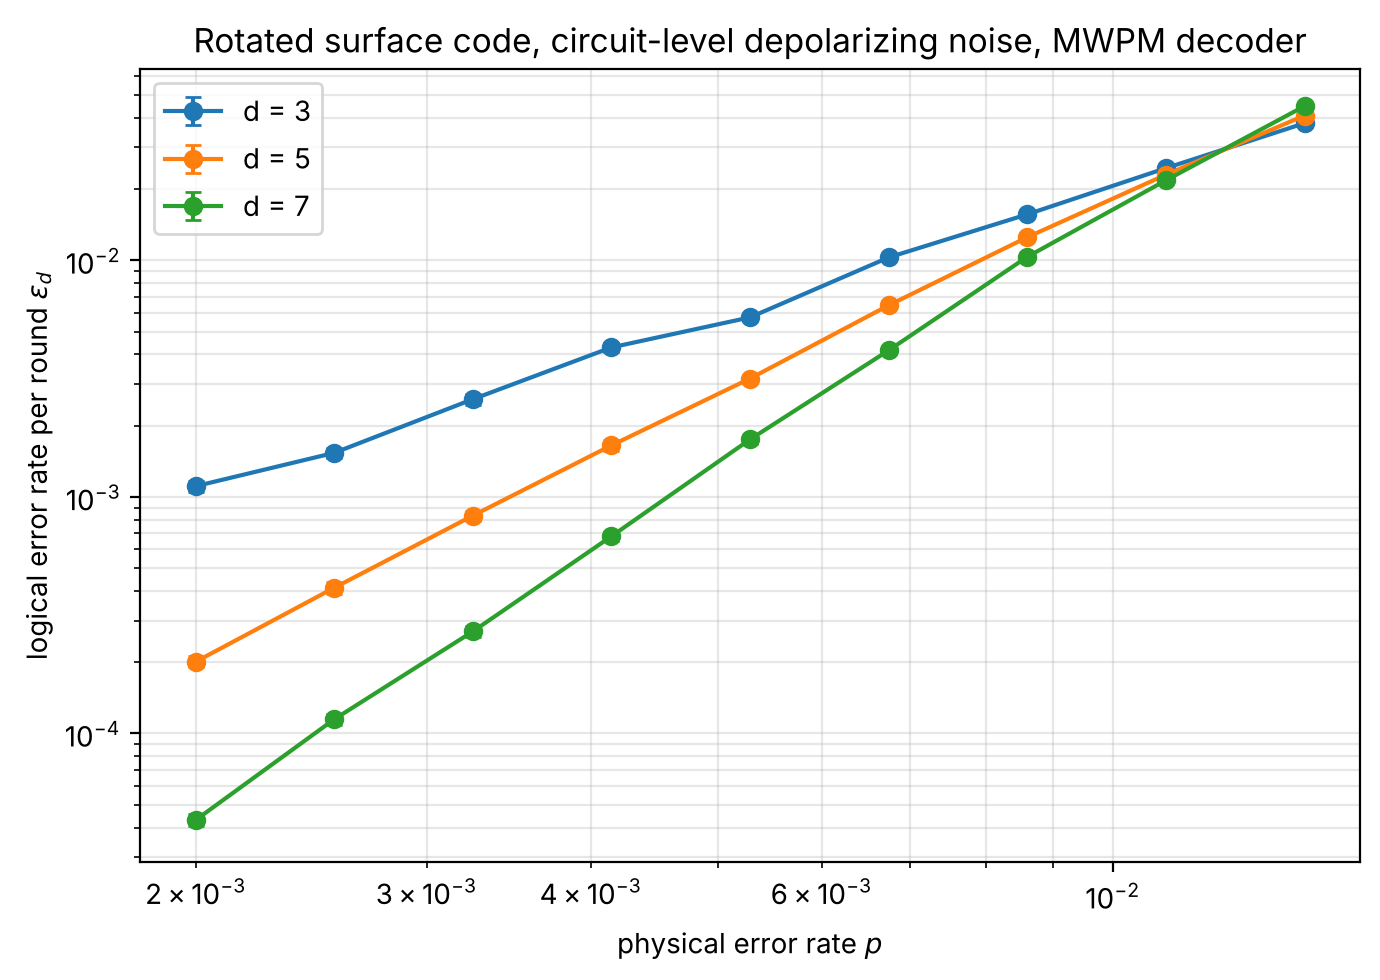

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
curves = {}
for d in distances:
    P = np.array([results[(d, p)][0] / results[(d, p)][1] for p in ps])
    N = np.array([results[(d, p)][1] for p in ps])
    sig = np.sqrt(P * (1 - P) / N)
    eps = per_round(P, d)
    lo = eps - per_round(np.clip(P - sig, 0, None), d)
    hi = per_round(P + sig, d) - eps
    curves[d] = eps
    ax.errorbar(ps, eps, yerr=[lo, hi], marker="o", capsize=3, label=f"d = {d}")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("physical error rate $p$")
ax.set_ylabel(r"logical error rate per round $\varepsilon_d$")
ax.set_title("Rotated surface code, circuit-level depolarizing noise, MWPM decoder")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("threshold_plot.png", dpi=150)
plt.show()

### Threshold estimate

The threshold is where the curves cross: below it a larger code is better, above it worse. We estimate it from the crossing of the $d=3$ and $d=7$ curves (interpolating $\log\varepsilon$ linearly in $\log p$).

In [8]:
def crossing(x, y1, y2):
    lx, f = np.log(x), np.log(y1) - np.log(y2)
    i = np.where(np.sign(f[:-1]) != np.sign(f[1:]))[0]
    if len(i) == 0:
        return None
    i = i[0]
    return float(np.exp(lx[i] - f[i] * (lx[i+1] - lx[i]) / (f[i+1] - f[i])))

for a, b in [(3, 5), (5, 7), (3, 7)]:
    x = crossing(ps, curves[a], curves[b])
    print(f"crossing d={a} / d={b}: p ≈ {x:.4%}" if x else f"no crossing d={a}/{b} in range")

crossing d=3 / d=5: p ≈ 1.2279%
crossing d=5 / d=7: p ≈ 1.2021%
crossing d=3 / d=7: p ≈ 1.2146%


## 5. Below threshold: error-suppression factor $\Lambda$

Below threshold, $\varepsilon_d \approx A\,(p/p_{th})^{(d+1)/2}$, so every increase $d \to d+2$ divides the logical error rate by a constant factor $\Lambda$. This is the figure of merit used in recent hardware experiments (e.g. Google's below-threshold surface-code demonstrations).

In [9]:
p_low = ps[0]
print(f"at p = {p_low:.3%}:")
for a, b in [(3, 5), (5, 7)]:
    lam = curves[a][0] / curves[b][0]
    print(f"  Lambda_{a}->{b} = eps_{a} / eps_{b} = {lam:.2f}")

# Scaling check: slope of log(eps) vs log(p) below threshold should be ~ (d+1)/2
print("\nlow-p slope of log(eps_d) vs log(p)  (theory: (d+1)/2)")
for d in distances:
    k = 3
    slope = np.polyfit(np.log(ps[:k]), np.log(curves[d][:k]), 1)[0]
    print(f"  d={d}: fitted slope {slope:.2f}   theory {(d+1)/2:.1f}")

at p = 0.200%:
  Lambda_3->5 = eps_3 / eps_5 = 5.53
  Lambda_5->7 = eps_5 / eps_7 = 4.67

low-p slope of log(eps_d) vs log(p)  (theory: (d+1)/2)
  d=3: fitted slope 1.74   theory 2.0
  d=5: fitted slope 2.92   theory 3.0
  d=7: fitted slope 3.77   theory 4.0


## 6. A neural-network decoder

**Why look beyond MWPM?** Matching needs a *graph*: every fault must flip at most two detectors. To get one, the DEM above was built with `decompose_errors=True`, which splits each $Y$ error into an independent $X$ part and $Z$ part. The decoder therefore ignores that these two parts come together, and loses information. *Correlated matching* (PyMatching ≥ 2.3) partially repairs this with a second, reweighted matching pass.

A neural network makes no such modelling assumption: it learns the map *syndrome history → logical flip* directly from samples. This is the idea behind recent neural decoders such as Google DeepMind's AlphaQubit. The questions are whether it actually beats matching, how its cost grows with $d$, and whether it is fast enough for **real-time** decoding.

**Learning problem.** For one shot, the input is the vector of detector outcomes ($24$ bits at $d=3$, $120$ at $d=5$) and the label is whether the logical observable flipped. This is a binary classification trained with a cross-entropy loss; the decoder predicts a flip when the network's output probability exceeds $1/2$.

**Data.** Stim samples are free, so instead of a fixed dataset the network sees a *fresh* batch at every step: overfitting is impossible and the only budget is compute. Training mixes several noise strengths so that one network works across the whole range of $p$; training only at low $p$ would fail, because logical flips are then so rare that always answering "no flip" already looks accurate.

In [10]:
class SyndromeStream:
    # Infinite stream of fresh (detector outcomes, logical flip) pairs from Stim,
    # drawn in equal parts from several noise strengths.
    def __init__(self, d, noise_levels, seed):
        self.samplers = [surface_code_circuit(d, p).compile_detector_sampler(seed=seed + i)
                         for i, p in enumerate(noise_levels)]

    def sample(self, n):
        k = n // len(self.samplers)
        draws = [s.sample(k, separate_observables=True) for s in self.samplers]
        det = np.concatenate([a for a, _ in draws]).astype(np.float32)
        obs = np.concatenate([b for _, b in draws]).astype(np.float32)
        return torch.from_numpy(det), torch.from_numpy(obs)

train_ps = np.geomspace(2e-3, 1.2e-2, 8)   # training mixture, covers the benchmark range
x, y = SyndromeStream(3, train_ps, seed=rng_seed).sample(80_000)
print(f"d=3 input: {x.shape[1]} detectors per shot")
print(f"fraction of shots with a logical flip (before decoding): {y.mean():.1%}")
print(f"mean number of fired detectors per shot: {x.sum(1).mean():.2f}")

d=3 input: 24 detectors per shot
fraction of shots with a logical flip (before decoding): 11.6%
mean number of fired detectors per shot: 1.57


### 6.1 Model and training loop

A fully connected network (MLP) with ReLU activations, a single output logit, Adam with a one-cycle learning-rate schedule, and batches of 2,048 fresh shots. Every `eval_every` steps the network decodes a fixed validation set at $p = 0.5\%$ (a seed never used for training), so we can follow its logical error rate against MWPM's on the same shots.

In [11]:
def make_mlp(n_in, width, depth):
    layers, w = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(w, width), nn.ReLU()]
        w = width
    layers.append(nn.Linear(w, 1))   # logit of P(logical flip | syndrome)
    return nn.Sequential(*layers)

@torch.no_grad()
def nn_predict(net, det, batch=16_384):
    # Boolean prediction of the logical flip for each shot (det: uint8/bool array of detector outcomes).
    net.eval()
    out = [net(torch.from_numpy(det[i:i + batch].astype(np.float32)))[:, 0] > 0
           for i in range(0, len(det), batch)]
    return torch.cat(out).numpy()

def train_decoder(d, width, depth, steps, batch=2048, lr=2e-3, p_val=5e-3, eval_every=1000):
    stream = SyndromeStream(d, train_ps, seed=rng_seed)
    val_circuit = surface_code_circuit(d, p_val)
    val_det, val_obs = val_circuit.compile_detector_sampler(seed=rng_seed + 500).sample(
        100_000, separate_observables=True)
    mwpm = pymatching.Matching.from_detector_error_model(val_circuit.detector_error_model(decompose_errors=True))
    mwpm_val = np.mean(mwpm.decode_batch(val_det)[:, 0] != val_obs[:, 0])

    net = make_mlp(val_circuit.num_detectors, width, depth)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    loss_fn = nn.BCEWithLogitsLoss()
    n_params = sum(p.numel() for p in net.parameters())
    print(f"d={d}: MLP {depth}x{width}, {n_params:,} parameters, {steps:,} steps x {batch} shots")

    history, running, t0 = [], [], time.time()
    for step in range(1, steps + 1):
        x, y = stream.sample(batch)
        net.train()
        loss = loss_fn(net(x), y)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        running.append(loss.item())
        if step % eval_every == 0:
            val_ler = np.mean(nn_predict(net, val_det) != val_obs[:, 0])
            history.append((step, np.mean(running), val_ler))
            running = []
            print(f"  step {step:6d}  loss {history[-1][1]:.4f}  val P_L {val_ler:.3%}  "
                  f"(MWPM {mwpm_val:.3%})  {time.time() - t0:5.0f} s")
    return net, history, mwpm_val

def plot_history(history, mwpm_val, d):
    steps, losses, lers = map(np.array, zip(*history))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(steps, losses, marker="o")
    ax[0].set_xlabel("training step"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title(f"d = {d}: training loss")
    ax[1].plot(steps, lers, marker="o", label="neural network")
    ax[1].axhline(mwpm_val, color="k", ls="--", label="MWPM")
    ax[1].set_xlabel("training step"); ax[1].set_ylabel("logical error probability $P_L$")
    ax[1].set_title(f"d = {d}: validation at p = 0.5%"); ax[1].legend()
    for a in ax: a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

### 6.2 Training at $d = 3$

d=3: MLP 3x256, 138,241 parameters, 15,000 steps x 2048 shots


  step   1000  loss 0.2240  val P_L 2.608%  (MWPM 1.703%)     10 s


  step   2000  loss 0.0826  val P_L 1.717%  (MWPM 1.703%)     19 s


  step   3000  loss 0.0749  val P_L 1.613%  (MWPM 1.703%)     29 s


  step   4000  loss 0.0728  val P_L 1.601%  (MWPM 1.703%)     38 s


  step   5000  loss 0.0716  val P_L 1.541%  (MWPM 1.703%)     47 s


... (6 outputs left out)

  step  12000  loss 0.0685  val P_L 1.491%  (MWPM 1.703%)    113 s


  step  13000  loss 0.0686  val P_L 1.476%  (MWPM 1.703%)    122 s


  step  14000  loss 0.0677  val P_L 1.472%  (MWPM 1.703%)    131 s


  step  15000  loss 0.0675  val P_L 1.471%  (MWPM 1.703%)    141 s


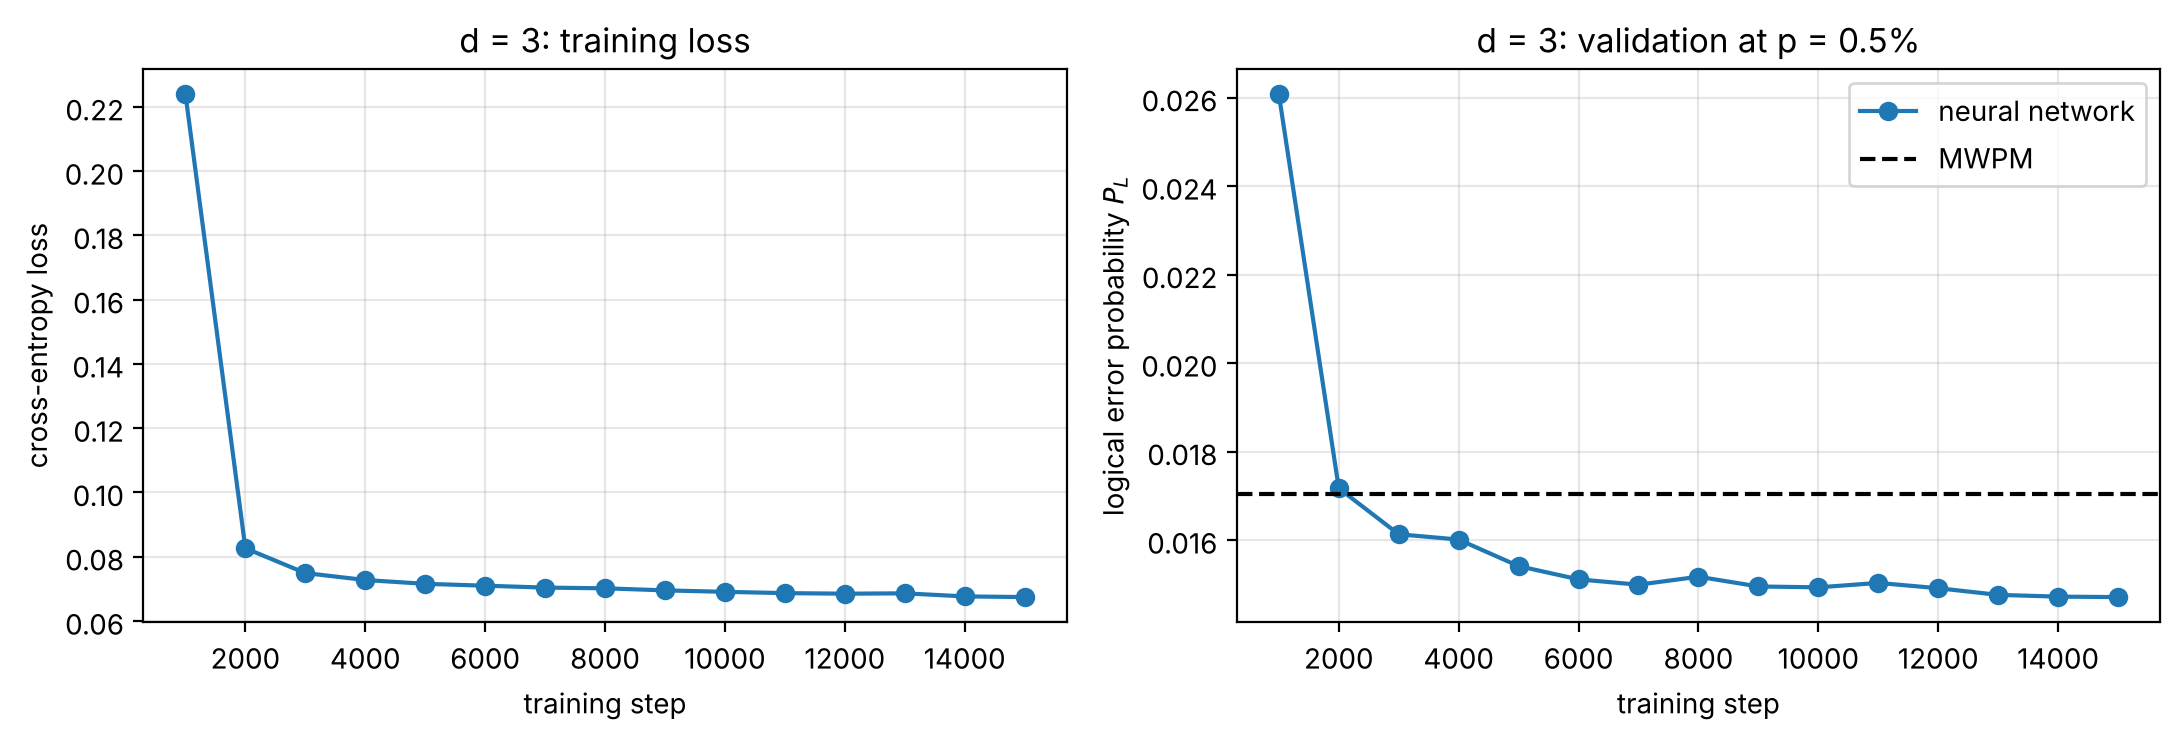

In [12]:
net3, hist3, mwpm_val3 = train_decoder(d=3, width=256, depth=3, steps=15_000)
plot_history(hist3, mwpm_val3, d=3)

## 7. Benchmark: neural network vs. MWPM vs. correlated MWPM

All three decoders see **exactly the same test syndromes** (a seed never used in training), so their differences are not sampling noise between independent runs. Besides the logical error rates we count the *disagreements*: shots that only the network gets wrong vs. shots that only MWPM gets wrong. If the network were no better than MWPM, these two counts would be equal up to statistical fluctuations of order $\sqrt{n}$.

Error rates are reported per round, $\varepsilon_d$, as in Section 4.

d = 3   (P_L = logical error probability over 3 rounds, 300,000 shots per point)
      p |     MWPM | corr. MWPM | neural net | NN / MWPM | NN-only / MWPM-only errors
 0.0020 |   0.302% |     0.329% |     0.257% |      0.85 |    106 / 242
 0.0028 |   0.590% |     0.632% |     0.488% |      0.83 |    179 / 484
 0.0040 |   1.096% |     1.039% |     0.933% |      0.85 |    438 / 927
 0.0056 |   2.104% |     2.044% |     1.828% |      0.87 |    819 / 1646
 0.0078 |   3.883% |     3.744% |     3.428% |      0.88 |   1633 / 2999
 0.0110 |   6.965% |     6.861% |     6.298% |      0.90 |   3239 / 5239


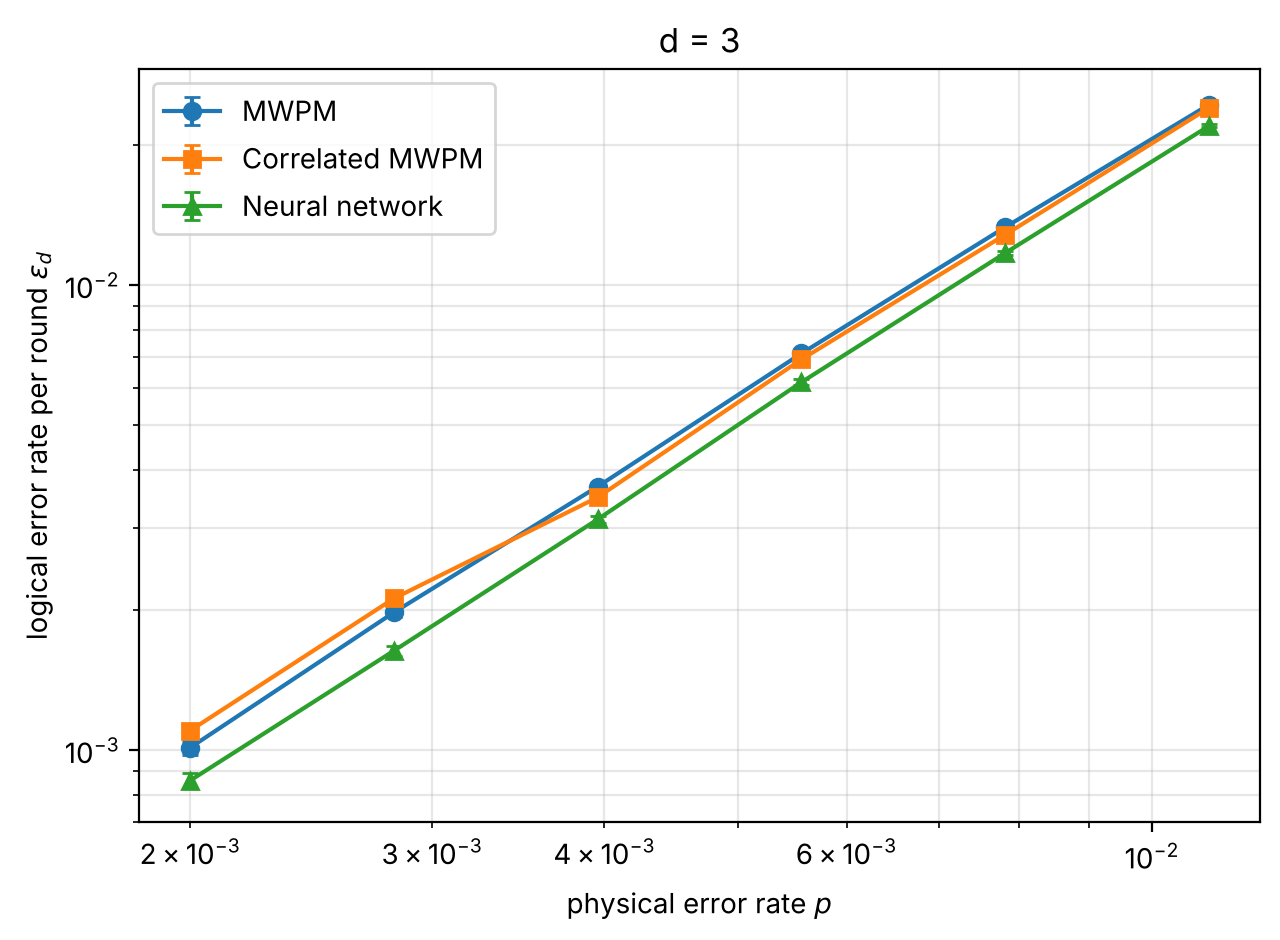

In [13]:
eval_ps = np.geomspace(2e-3, 1.1e-2, 6)
DECODERS = ["MWPM", "Correlated MWPM", "Neural network"]

def benchmark(d, net, noise_levels=eval_ps, shots=300_000, seed=rng_seed + 1000):
    rows = []
    for p in noise_levels:
        circuit = surface_code_circuit(d, p)
        dem = circuit.detector_error_model(decompose_errors=True)
        mwpm = pymatching.Matching.from_detector_error_model(dem)
        corr = pymatching.Matching.from_detector_error_model(dem, enable_correlations=True)
        det, obs = circuit.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
        obs = obs[:, 0]
        wrong = {
            "MWPM": mwpm.decode_batch(det)[:, 0] != obs,
            "Correlated MWPM": corr.decode_batch(det, enable_correlations=True)[:, 0] != obs,
            "Neural network": nn_predict(net, det) != obs,
        }
        row = {"p": p, "shots": shots, **{k: v.mean() for k, v in wrong.items()},
               "nn_only": int(np.sum(wrong["Neural network"] & ~wrong["MWPM"])),
               "mwpm_only": int(np.sum(wrong["MWPM"] & ~wrong["Neural network"]))}
        rows.append(row)
    print(f"d = {d}   (P_L = logical error probability over {d} rounds, {shots:,} shots per point)")
    print(f"{'p':>7} | {'MWPM':>8} | {'corr. MWPM':>10} | {'neural net':>10} | {'NN / MWPM':>9} | NN-only / MWPM-only errors")
    for r in rows:
        print(f"{r['p']:7.4f} | {r['MWPM']:8.3%} | {r['Correlated MWPM']:10.3%} | {r['Neural network']:10.3%} | "
              f"{r['Neural network'] / r['MWPM']:9.2f} | {r['nn_only']:6d} / {r['mwpm_only']}")
    return rows

def plot_benchmark(rows, d, ax):
    ps_ = np.array([r["p"] for r in rows]); n = rows[0]["shots"]
    for name, marker in zip(DECODERS, ["o", "s", "^"]):
        P = np.array([r[name] for r in rows])
        sig = np.sqrt(P * (1 - P) / n)
        eps = per_round(P, d)
        lo = eps - per_round(np.clip(P - sig, 0, None), d)
        hi = per_round(P + sig, d) - eps
        ax.errorbar(ps_, eps, yerr=[lo, hi], marker=marker, capsize=3, label=name)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("physical error rate $p$"); ax.set_ylabel(r"logical error rate per round $\varepsilon_d$")
    ax.set_title(f"d = {d}"); ax.grid(True, which="both", alpha=0.3); ax.legend()

rows3 = benchmark(3, net3)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
plot_benchmark(rows3, 3, ax)
plt.tight_layout(); plt.show()

### 7.1 Scaling up: $d = 5$

The input grows from 24 to 120 detectors, and the number of distinct syndromes the network must learn to classify grows exponentially. We keep the same recipe with a wider, deeper network. Training at $d = 5$ takes several minutes on a laptop CPU; increase `steps` (ideally on a GPU, e.g. Google Colab) to see how far the gap to MWPM closes.

d=5: MLP 4x512, 850,433 parameters, 12,000 steps x 2048 shots


  step   1000  loss 0.3627  val P_L 7.540%  (MWPM 1.465%)     43 s


  step   2000  loss 0.2155  val P_L 6.236%  (MWPM 1.465%)     87 s


  step   3000  loss 0.1837  val P_L 4.766%  (MWPM 1.465%)    133 s


  step   4000  loss 0.1547  val P_L 3.370%  (MWPM 1.465%)    179 s


  step   5000  loss 0.1355  val P_L 2.784%  (MWPM 1.465%)    227 s


... (3 outputs left out)

  step   9000  loss 0.1061  val P_L 1.918%  (MWPM 1.465%)    425 s


  step  10000  loss 0.1023  val P_L 1.840%  (MWPM 1.465%)    476 s


  step  11000  loss 0.1000  val P_L 1.790%  (MWPM 1.465%)    526 s


  step  12000  loss 0.0990  val P_L 1.783%  (MWPM 1.465%)    576 s


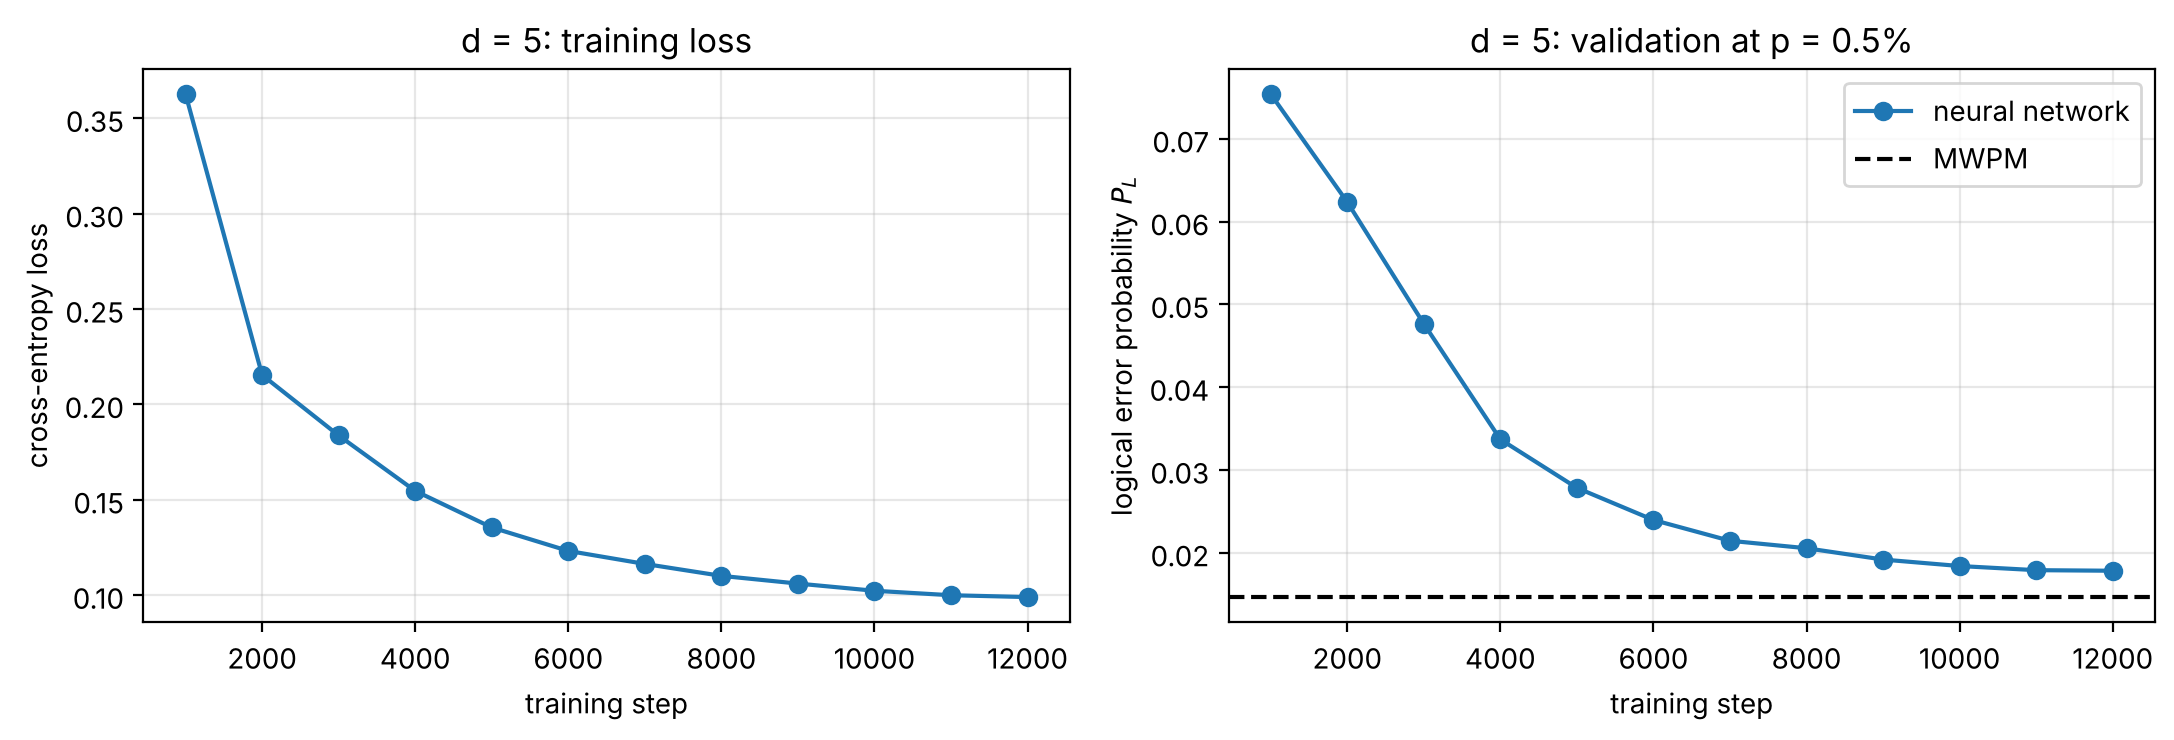

d = 5   (P_L = logical error probability over 5 rounds, 300,000 shots per point)
      p |     MWPM | corr. MWPM | neural net | NN / MWPM | NN-only / MWPM-only errors
 0.0020 |   0.105% |     0.073% |     0.120% |      1.14 |    174 / 129
 0.0028 |   0.275% |     0.206% |     0.335% |      1.22 |    473 / 291
 0.0040 |   0.760% |     0.551% |     0.942% |      1.24 |   1403 / 858
 0.0056 |   1.887% |     1.505% |     2.447% |      1.30 |   3752 / 2070
 0.0078 |   4.605% |     3.862% |     5.864% |      1.27 |   9004 / 5227
 0.0110 |  10.384% |     9.270% |    13.273% |      1.28 |  20417 / 11751


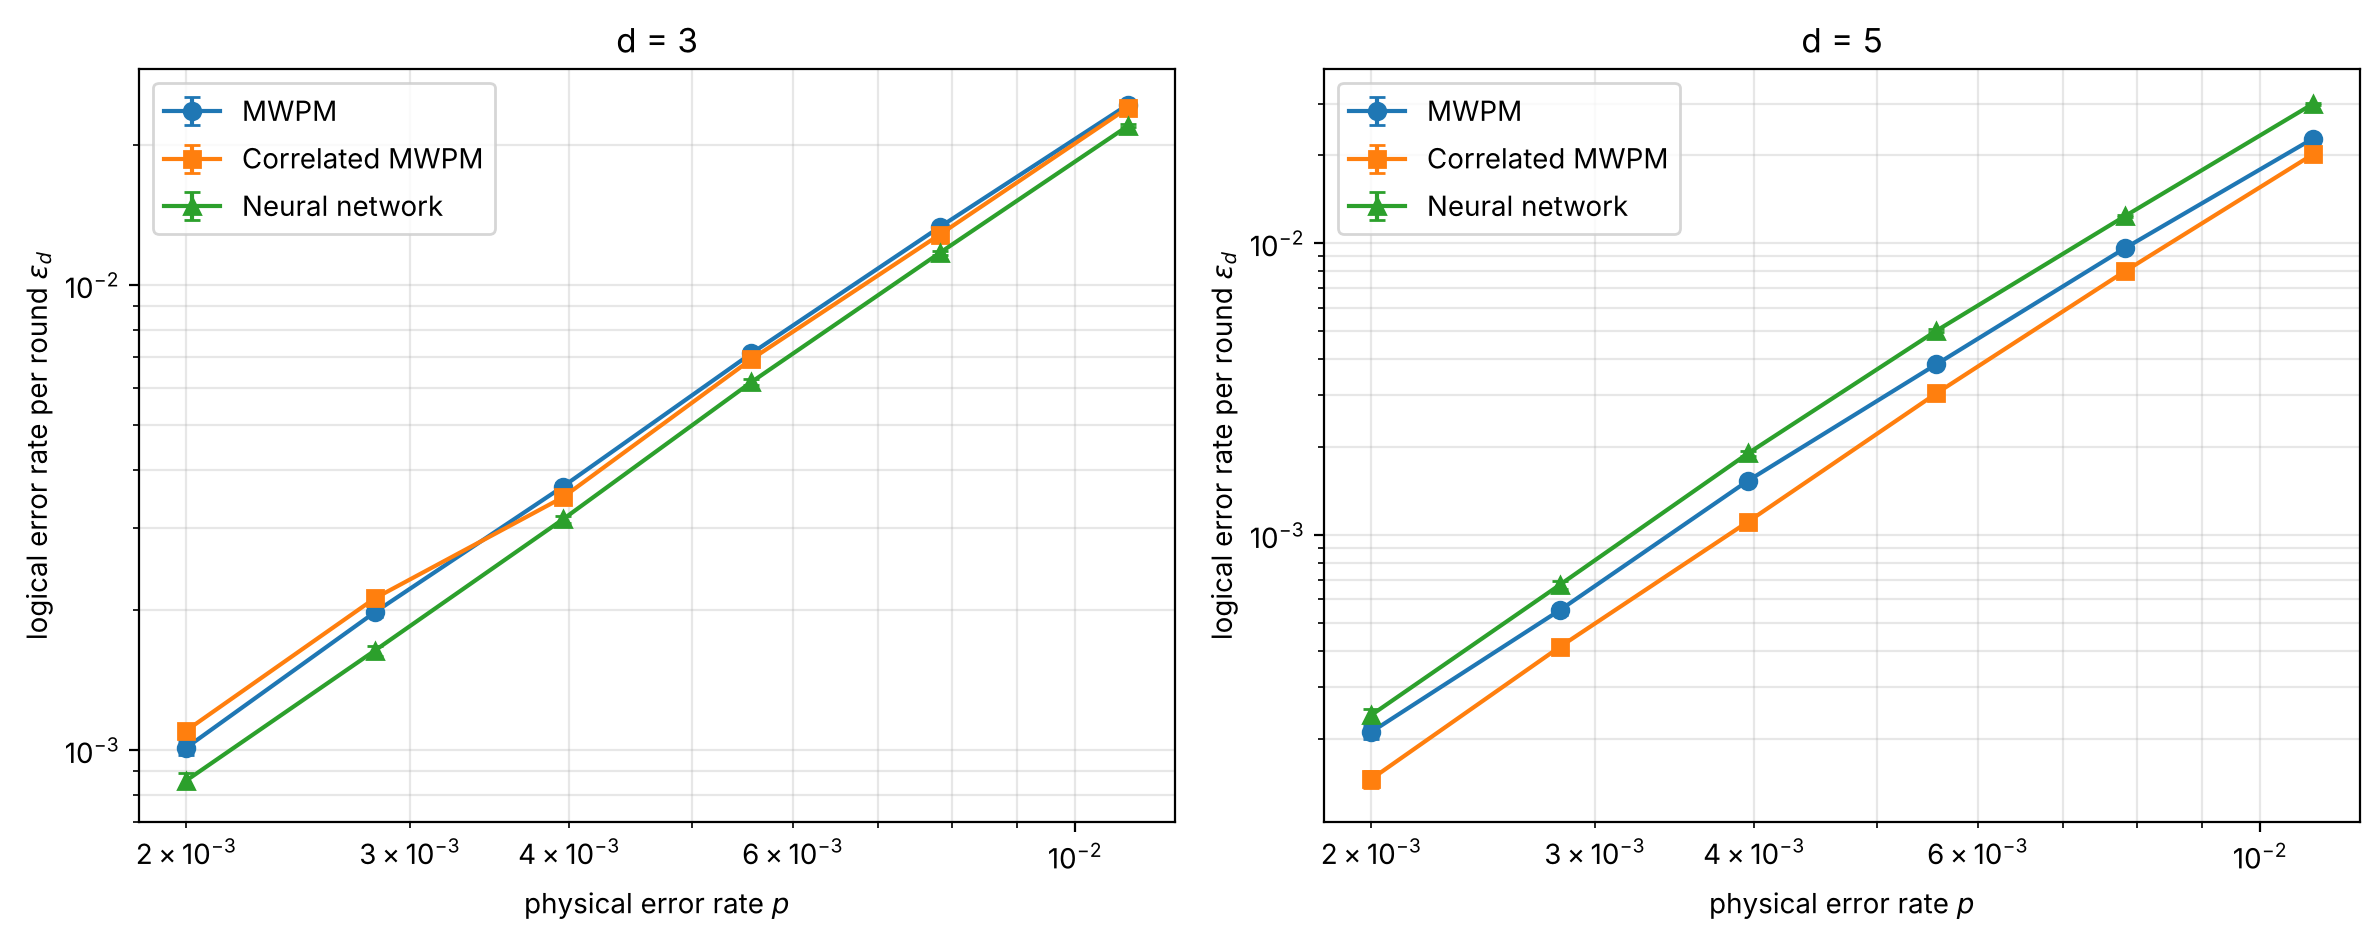

In [14]:
net5, hist5, mwpm_val5 = train_decoder(d=5, width=512, depth=4, steps=12_000)
plot_history(hist5, mwpm_val5, d=5)

rows5 = benchmark(5, net5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
plot_benchmark(rows3, 3, axes[0])
plot_benchmark(rows5, 5, axes[1])
plt.tight_layout(); plt.savefig("decoder_benchmark.png", dpi=150); plt.show()

## 8. Latency: can it decode in real time?

A fault-tolerant computer produces a new round of syndrome data at a fixed rate (on superconducting hardware, roughly once per microsecond), and the decoder has to keep up or a backlog builds. We measure two regimes on this CPU:
- **one syndrome at a time** (the streaming situation), and
- **large batches** (throughput, the offline-simulation situation).

These numbers depend on the machine and on software overhead (Python calls dominate single-shot PyTorch inference), so they say more about orders of magnitude than about the hardware limit.

In [15]:
def latency_table(d, net, p=5e-3, n_single=2_000, n_batch=200_000):
    circuit = surface_code_circuit(d, p)
    dem = circuit.detector_error_model(decompose_errors=True)
    mwpm = pymatching.Matching.from_detector_error_model(dem)
    det, _ = circuit.compile_detector_sampler(seed=rng_seed + 2000).sample(n_batch, separate_observables=True)
    single = det[:n_single]
    torch_single = torch.from_numpy(single.astype(np.float32))

    t = time.perf_counter()
    for s in single: mwpm.decode(s)
    mwpm_single = (time.perf_counter() - t) / n_single

    net.eval()
    with torch.no_grad():
        t = time.perf_counter()
        for i in range(n_single): net(torch_single[i:i + 1])
        nn_single = (time.perf_counter() - t) / n_single

    t = time.perf_counter(); mwpm.decode_batch(det); mwpm_batch = (time.perf_counter() - t) / n_batch
    t = time.perf_counter(); nn_predict(net, det); nn_batch = (time.perf_counter() - t) / n_batch

    print(f"d = {d}, p = {p:.1%}   time per syndrome (microseconds)")
    print(f"  {'':16s}{'single shot':>12s}{'batched':>10s}")
    print(f"  {'MWPM':16s}{mwpm_single * 1e6:12.2f}{mwpm_batch * 1e6:10.2f}")
    print(f"  {'Neural network':16s}{nn_single * 1e6:12.2f}{nn_batch * 1e6:10.2f}")

n_threads = torch.get_num_threads()
torch.set_num_threads(1)   # single-core comparison, like PyMatching
latency_table(3, net3)
latency_table(5, net5)
torch.set_num_threads(n_threads)

d = 3, p = 0.5%   time per syndrome (microseconds)
                   single shot   batched
  MWPM                    3.84      0.29
  Neural network         41.43      2.76


d = 5, p = 0.5%   time per syndrome (microseconds)
                   single shot   batched
  MWPM                    7.39      3.14
  Neural network        159.55     14.19


## 9. Takeaways and next steps

**Matching baseline (Sections 1–5)**
- With uniform circuit-level depolarizing noise (no idle errors) and an MWPM decoder, the curves cross at **$p_{th} \approx 1.2\%$** (per-round logical error rate), in the ~1% range usually quoted for this noise model; idle errors or a hardware-like model (e.g. SI1000) push it down to ~0.5–0.7%.
- Below threshold the logical error rate is suppressed exponentially with distance: at $p = 0.2\%$, $\Lambda \approx 5$, and the fitted slopes approach $(d+1)/2$ as $p \to 0$.
- The circuit-level distance equals $d$: the default CNOT schedule has no distance-reducing hook errors.

**Neural-network decoder (Sections 6–8)**
- **At $d = 3$ the network beats matching.** Trained in about two minutes on a laptop CPU, the MLP has a logical error rate about **10–17% lower than MWPM** at every noise strength tested, and is also below correlated MWPM. The paired comparison makes this solid: on the same shots, MWPM fails roughly twice as often where the network succeeds as the reverse, far beyond $\sqrt{n}$ fluctuations. With only 24 detectors, the network can learn what the graph decomposition throws away (the $X$–$Z$ correlations of $Y$ errors and of hook errors) and get close to the optimal maximum-likelihood decoder.
- **At $d = 5$ it does not, yet.** With the same recipe and about ten minutes of CPU training, the network is **15–30% worse than MWPM**, while correlated MWPM is the best decoder. The validation curve is still going down, so this is a compute limit rather than a plateau, but it illustrates the central difficulty of neural decoders: the syndrome space grows exponentially with $d$, and a generic MLP has to learn the code's geometry from scratch.
- **Latency is the other cost.** On one CPU core, single-shot inference is roughly 10–20 times slower than PyMatching (tens to hundreds of microseconds vs. a few). Neither meets the ~1 µs-per-round budget of superconducting hardware from Python; real-time neural decoding requires small, structured models running on dedicated hardware (FPGA, ASIC or GPU) with streaming inputs.
- Correlated matching is not a free lunch either: at $d = 3$ and low $p$ it is slightly worse than plain MWPM, whereas at $d = 5$ it gains 20–30%.

**Next steps**
1. **Architectures that exploit the code's structure.** A convolutional network is translation-invariant and can share weights across distances; a recurrent or transformer model that consumes one round at a time (as in AlphaQubit) is the natural form for streaming, real-time decoding.
2. **Reinforcement learning.** Cast decoding as a sequential decision problem: an agent proposes corrections round by round and is rewarded when the logical state survives, which removes the need for labelled data and suits real-time operation.
3. **Noise the matching model does not know.** The strongest argument for learned decoders is hardware noise outside the DEM: leakage, correlated or drifting errors, non-uniform qubits, or photon loss in photonic architectures. Training on such data, or fine-tuning on experimental syndromes, is where a network can beat any model-based decoder.
4. **Scaling compute.** GPU training, larger batches and a curriculum from $d = 3$ to $d = 5$ and beyond, to measure how the training cost needed to match MWPM grows with $d$.
5. **Other codes.** The same pipeline applies to qLDPC codes (e.g. bivariate bicycle codes), where the standard decoder is BP-OSD and learned decoders are an active research topic.